# running a simulation on the knot-chain

### generate a braid closure to have a knot for the simulations

In [1]:
from geometry_mnist.knotgen.braidclosure import generate_braid_closure
from geometry_mnist.knotgen.braidclosure import resample_normalize_chain
from geometry_mnist.plotly.plots import plot_pts

word          = [1,-2,1,3,2,2,-4,-3,2,-3,-3,-4] # word must be 1-indexed to hold sign+braid_id. 
n_pts_per_ops = 30
n_resample    = 512

pts_raw       = generate_braid_closure(word, n_pts_per_ops)
pts_resampled = resample_normalize_chain(pts_raw, n_resample)

plot_pts(pts_resampled, kos_len=0.05)

### what is 1 step

In [2]:
# ===== inputs { (bundle into objects! EnergyW, ControlParams, Pts+PrecomputedOnPts, T)
#     points or state, l_0_linklength,
#     dt_ceiling, safety_fractions (for relaxation max disp should activate, for T sim it should be dt_max)
#     WeightsE, T,
# }

# 1. ----- calculate the energy(x) E(x)

# 2. ----- Gradient

    # F = grad E with torch autograd on E(x)
    
    # precondition / smooth gradients with M_sobolev @ grads
    
# 3. ----- "dt" check (important params: dt_ceiling + strand_gap_fraction ~0.25 + link_change_fraction ~0.05-0.10)

    # compute a few things which are setting the limits (min_strand_separation, link_lenght(fixed))

    # for PUSH(gradient): get gradients, plug into update formula and get the displacement (kinda per unit dt)

        # strand-limit: max push must stay below minimum strand separation (strand_gap_frac * min_strand separation).
        # => find the largest dt that still respects this (dt = limit / push.max)

        # neighbour-limit: max point-to-point push DIFFERENCe must be considerably smaller than the link length (link_change_frac * link_length). this will rarely bind, as gradients are smoothed, except at the T=0 equilibrium where the only push left is uniform scaling.
        # => find the largest dt that still respects this (dt = limit / push.max)
        
    # for KICK(noise): here no noise is actually generated, only the statistic bulk properties are used to "compare" to the limits. basically needs an empirical "max" for the noise (included smoothing)
    
        # strand-limit: the expeccted displacement is (from the update formula):
        # noise_gain_per_point * sqrt(2 · T · dt / link_length)
        # => solve for largest dt admissible
        
        # neightbour-limit: the expected displacement is (from the update formula):
        # noise_gain_between_neighbours * sqrt(2 · T · dt / link_length)
        # => solve for largest dt admissible
        
    # find the smallest dt out of all these and the dt_ceiling => this is the effective dt!
    
# 4. ----- do update and addd noise (but with dt_eff which is the max allowed dt from before)

# 5. ----- contstraints

    # ropelength
    
    # mean
    
    # PBD links (to some tolerance!) (put this after rescaling, otherwise it will have to fight uniform scaling which it's reeeeally bad at)
    
    
# 6. ----- verify and retry? would catch: 

    # push + kick add up reeeeally unfavourably (compare their sum to the strand_gap_fraction * min_strand_sep again)
    # this also catches unuuusally large noise samples (unlikely after smoothing)
    
    # check largest link error after PBD (mainly check if that fails to converge)
    
# ===== return some outputs {
#     E (compare the change outside over multiple steps)
#     g (optional, for gradient viz...)
#     limiter info (dt and max_disp, which of the two was hit, actual used limit),
#     net displacement (for knowing when to halt sim)
#     nr of retries (if that is used)
#     x+1 points
# }

### the noise statistics (bulk properties with smoothing)

tensor(0.9596, dtype=torch.float64) tensor(0.1023, dtype=torch.float64)


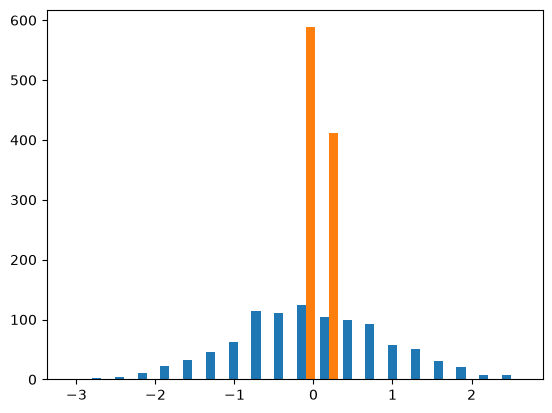

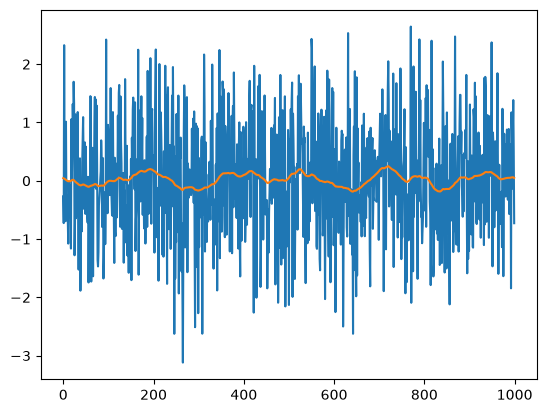

In [ ]:
import torch
import matplotlib.pyplot as plt
from geometry_mnist.knotgen.chain import construct_sobolev_kernel

n_pt0
A = construct_sobolev_kernel(n_pts, reach_percentage=0.02)

noise = torch.randn(size=(n_pts, ), dtype=torch.float64)
precond_noise = A@noise

print(noise.std(), precond_noise.std())

plt.figure()
_ = plt.hist([noise, precond_noise], bins=20)

plt.figure()
_ = plt.plot(noise)
_ = plt.plot(precond_noise)

### run the simulation

In [4]:
# define initial state as resampled points

# precalculate the things that are static (like sobolev mat)

# set energy params



# set loop params

# ===== main loop =====

    # run 1 step
    
    # x = x_next (necessary? maybe rewrite x (points) in step func?)
    
    # stop criterion (T=0 only) when E change and net displacement has stalled
    
    # logging and info


### optional stuff?

- also somehow get info about the gradients out -> that was quite important for debugging